#### Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score,root_mean_squared_error

import streamlit as st

import joblib

#### Load the Manufacturing Dataset

In [2]:
# Load the dataset
df = pd.read_csv(r"D:\Machine Leraning\TNS\capstone_project\manufacturing_data.csv")
print(f"shape of dataset {df.shape}") # shape of dtaset
display(df.head())
print(df.info()) # columns info (datatype ,missing values)


shape of dataset (1000, 19)


,Timestamp,Injection_Temperature,Injection_Pressure,Cycle_Time,Cooling_Time,Material_Viscosity,Ambient_Temperature,Machine_Age,Operator_Experience,Maintenance_Hours,Shift,Machine_Type,Material_Grade,Day_of_Week,Temperature_Pressure_Ratio,Total_Cycle_Time,Efficiency_Score,Machine_Utilization,Parts_Per_Hour
0,2023-01-01 00:00:00,221.0,136.0,28.7,13.6,375.5,28.0,3.8,11.2,64,Evening,Type_B,Economy,Thursday,1.625,42.3,0.063,0.510,36.5
1,2023-01-01 01:00:00,213.3,128.9,34.5,14.0,215.8,22.6,6.8,6.3,58,Night,Type_A,Standard,Wednesday,1.655,48.5,0.037,0.389,29.9
2,2023-01-01 02:00:00,222.8,115.9,19.9,9.5,307.0,25.3,4.2,9.6,47,Day,Type_A,Standard,Monday,1.922,29.4,0.061,0.551,56.9
3,2023-01-01 03:00:00,233.3,105.3,39.2,13.1,137.8,26.0,9.2,8.6,49,Evening,Type_A,Premium,Saturday,2.215,52.3,0.054,0.293,31.0++-
4,2023-01-01 04:00:00,212.2,125.5,45.0,9.9,298.2,23.6,6.2,23.0,49,Night,Type_B,Premium,Monday,1.691,54.9,0.145,0.443,15.0


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Timestamp                   1000 non-null   str    
 1   Injection_Temperature       1000 non-null   float64
 2   Injection_Pressure          1000 non-null   float64
 3   Cycle_Time                  1000 non-null   float64
 4   Cooling_Time                1000 non-null   float64
 5   Material_Viscosity          980 non-null    float64
 6   Ambient_Temperature         980 non-null    float64
 7   Machine_Age                 1000 non-null   float64
 8   Operator_Experience         980 non-null    float64
 9   Maintenance_Hours           1000 non-null   int64  
 10  Shift                       1000 non-null   str    
 11  Machine_Type                1000 non-null   str    
 12  Material_Grade              1000 non-null   str    
 13  Day_of_Week                 1000 non-null   s

#### Duplicate & Missing value check

In [3]:
print(f"no of duplicate Rows: {df.duplicated().sum()}")
print("Missing values: \n",df.isnull().sum())

no of duplicate Rows: 0
Missing values: 
 Timestamp                      0
Injection_Temperature          0
Injection_Pressure             0
Cycle_Time                     0
Cooling_Time                   0
Material_Viscosity            20
Ambient_Temperature           20
Machine_Age                    0
Operator_Experience           20
Maintenance_Hours              0
Shift                          0
Machine_Type                   0
Material_Grade                 0
Day_of_Week                    0
Temperature_Pressure_Ratio     0
Total_Cycle_Time               0
Efficiency_Score               0
Machine_Utilization            0
Parts_Per_Hour                 0
dtype: int64


#### Statistical summary of data

In [4]:
display(df.describe())

,Injection_Temperature,Injection_Pressure,Cycle_Time,Cooling_Time,Material_Viscosity,Ambient_Temperature,Machine_Age,Operator_Experience,Maintenance_Hours,Temperature_Pressure_Ratio,Total_Cycle_Time,Efficiency_Score,Machine_Utilization
count,1000.000000,1000.000000,1000.00000,1000.00000,980.000000,980.000000,1000.000000,980.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,215.315900,116.075000,35.85170,11.92320,251.630714,22.941224,7.855900,30.795204,50.580000,1.885852,47.737000,0.192688,0.356844
std,11.995507,14.667246,8.35349,2.30429,73.348695,2.773712,3.900798,27.684769,16.014558,0.274323,8.671153,0.173839,0.195610
min,180.000000,80.000000,16.30000,8.00000,104.600000,18.000000,1.000000,1.000000,26.000000,1.286000,24.600000,0.006000,0.001000
25%,207.200000,105.900000,28.80000,10.27500,200.900000,20.800000,4.700000,9.800000,45.000000,1.683750,41.000000,0.061000,0.193000
50%,215.300000,115.950000,36.85000,11.90000,242.700000,22.900000,7.900000,22.100000,50.000000,1.849500,48.550000,0.139000,0.355500
75%,222.800000,125.925000,45.00000,13.50000,295.300000,25.100000,11.100000,43.425000,55.000000,2.044250,55.300000,0.274000,0.520000
max,300.000000,150.000000,60.00000,19.90000,1000.000000,28.000000,15.000000,120.000000,500.000000,2.843000,64.900000,0.840000,0.755000


#### Clean Target Variable

In [5]:
df['Parts_Per_Hour'] = pd.to_numeric(
    df['Parts_Per_Hour'].astype(str).str.replace('+', '', regex=False),
    errors='coerce'
)
invalid_rows = df['Parts_Per_Hour'].isna().sum()
print('Invalid target rows removed:', invalid_rows)
df = df.dropna(subset=['Parts_Per_Hour']).copy()
print('Rows after target cleaning:', len(df))

Invalid target rows removed: 1
Rows after target cleaning: 999


#### Target Visualization

count    999.000000
mean      29.296396
std       11.961363
min        5.000000
25%       17.500000
50%       28.200000
75%       38.000000
max       68.600000
Name: Parts_Per_Hour, dtype: float64


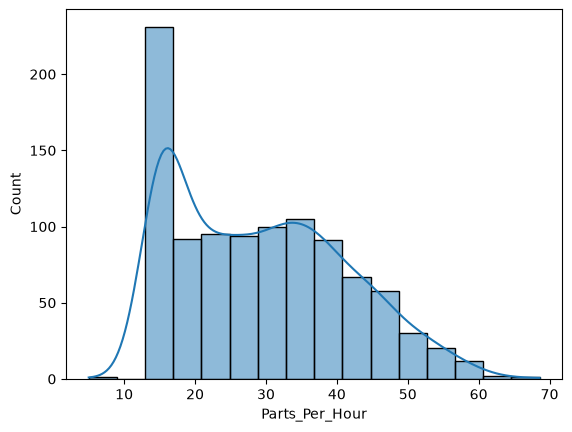

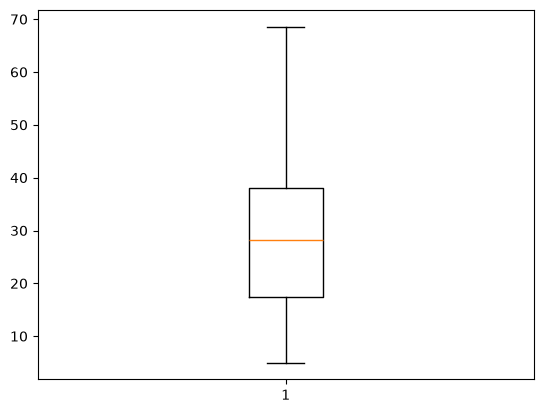

In [6]:

df["Parts_Per_Hour"]= df["Parts_Per_Hour"].astype(str).str.replace('+','',regex=False)
df["Parts_Per_Hour"]= pd.to_numeric(df["Parts_Per_Hour"],errors="coerce")
df= df.dropna(subset=["Parts_Per_Hour"])
print(df["Parts_Per_Hour"].describe())

plt.Figure(figsize=(8,5))
sns.histplot(df["Parts_Per_Hour"],kde=True) # distribution of target variable
plt.show()

plt.Figure(figsize=(6,3))
plt.boxplot(df["Parts_Per_Hour"]) # boxplot is used to identify possible outliers in target variable
plt.show()

#### Exploratory Data Analysis

Index(['Injection_Temperature', 'Injection_Pressure', 'Cycle_Time',
       'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature',
       'Machine_Age', 'Operator_Experience', 'Maintenance_Hours',
       'Temperature_Pressure_Ratio', 'Total_Cycle_Time', 'Efficiency_Score',
       'Machine_Utilization', 'Parts_Per_Hour'],
      dtype='str')


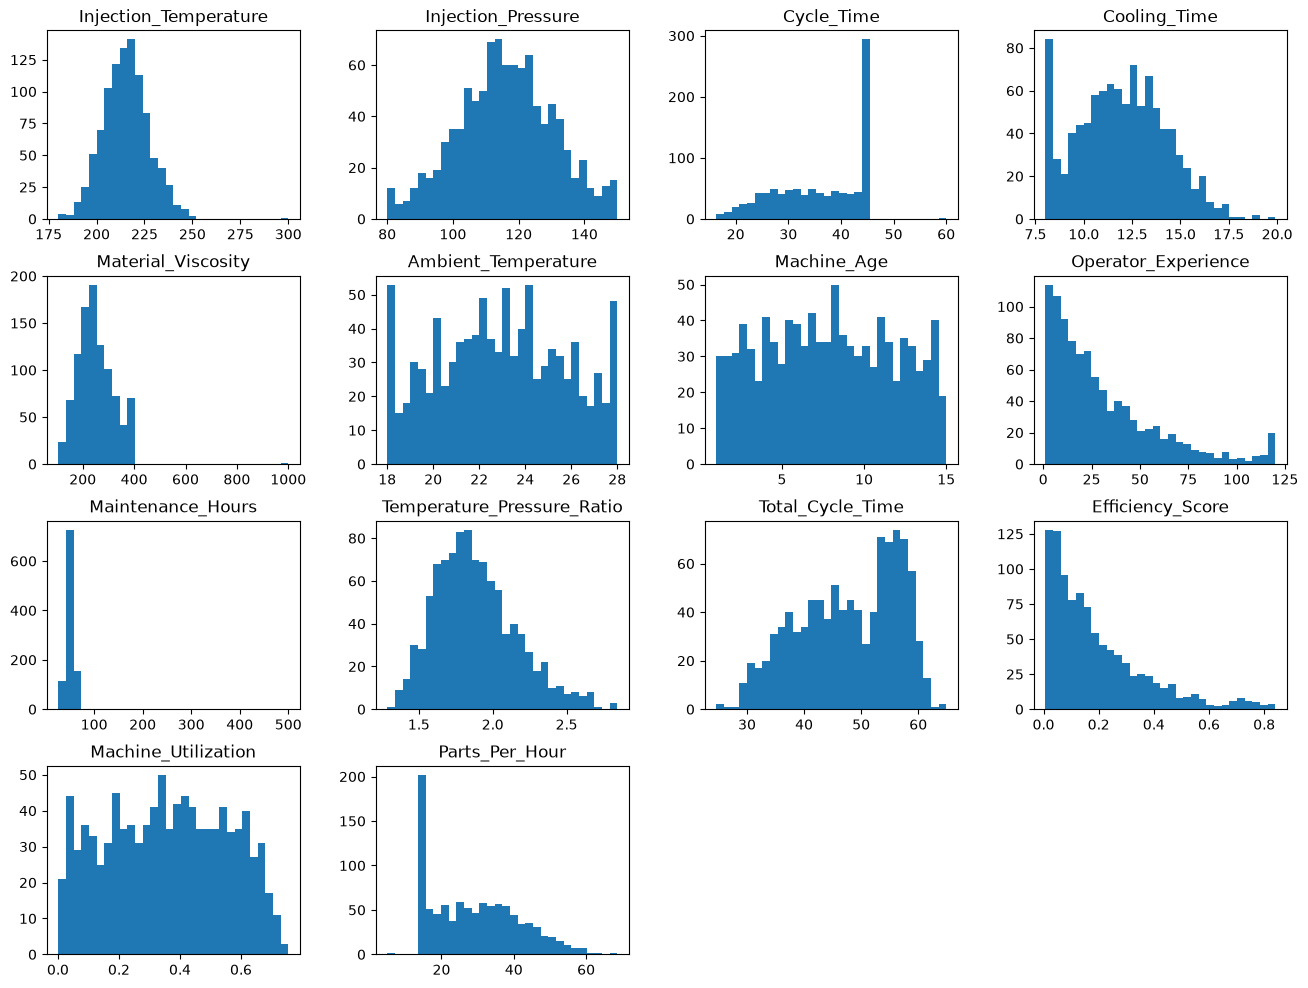

In [7]:

numerical_columns = df.select_dtypes(include=["int64","float64"]).columns
print(numerical_columns)
df[numerical_columns].hist(bins=30,figsize=(16,12),grid=False)
plt.show()

#### Scatter plot 
##### scatter plot shows relationship between each numerical feature and parts_per_hour

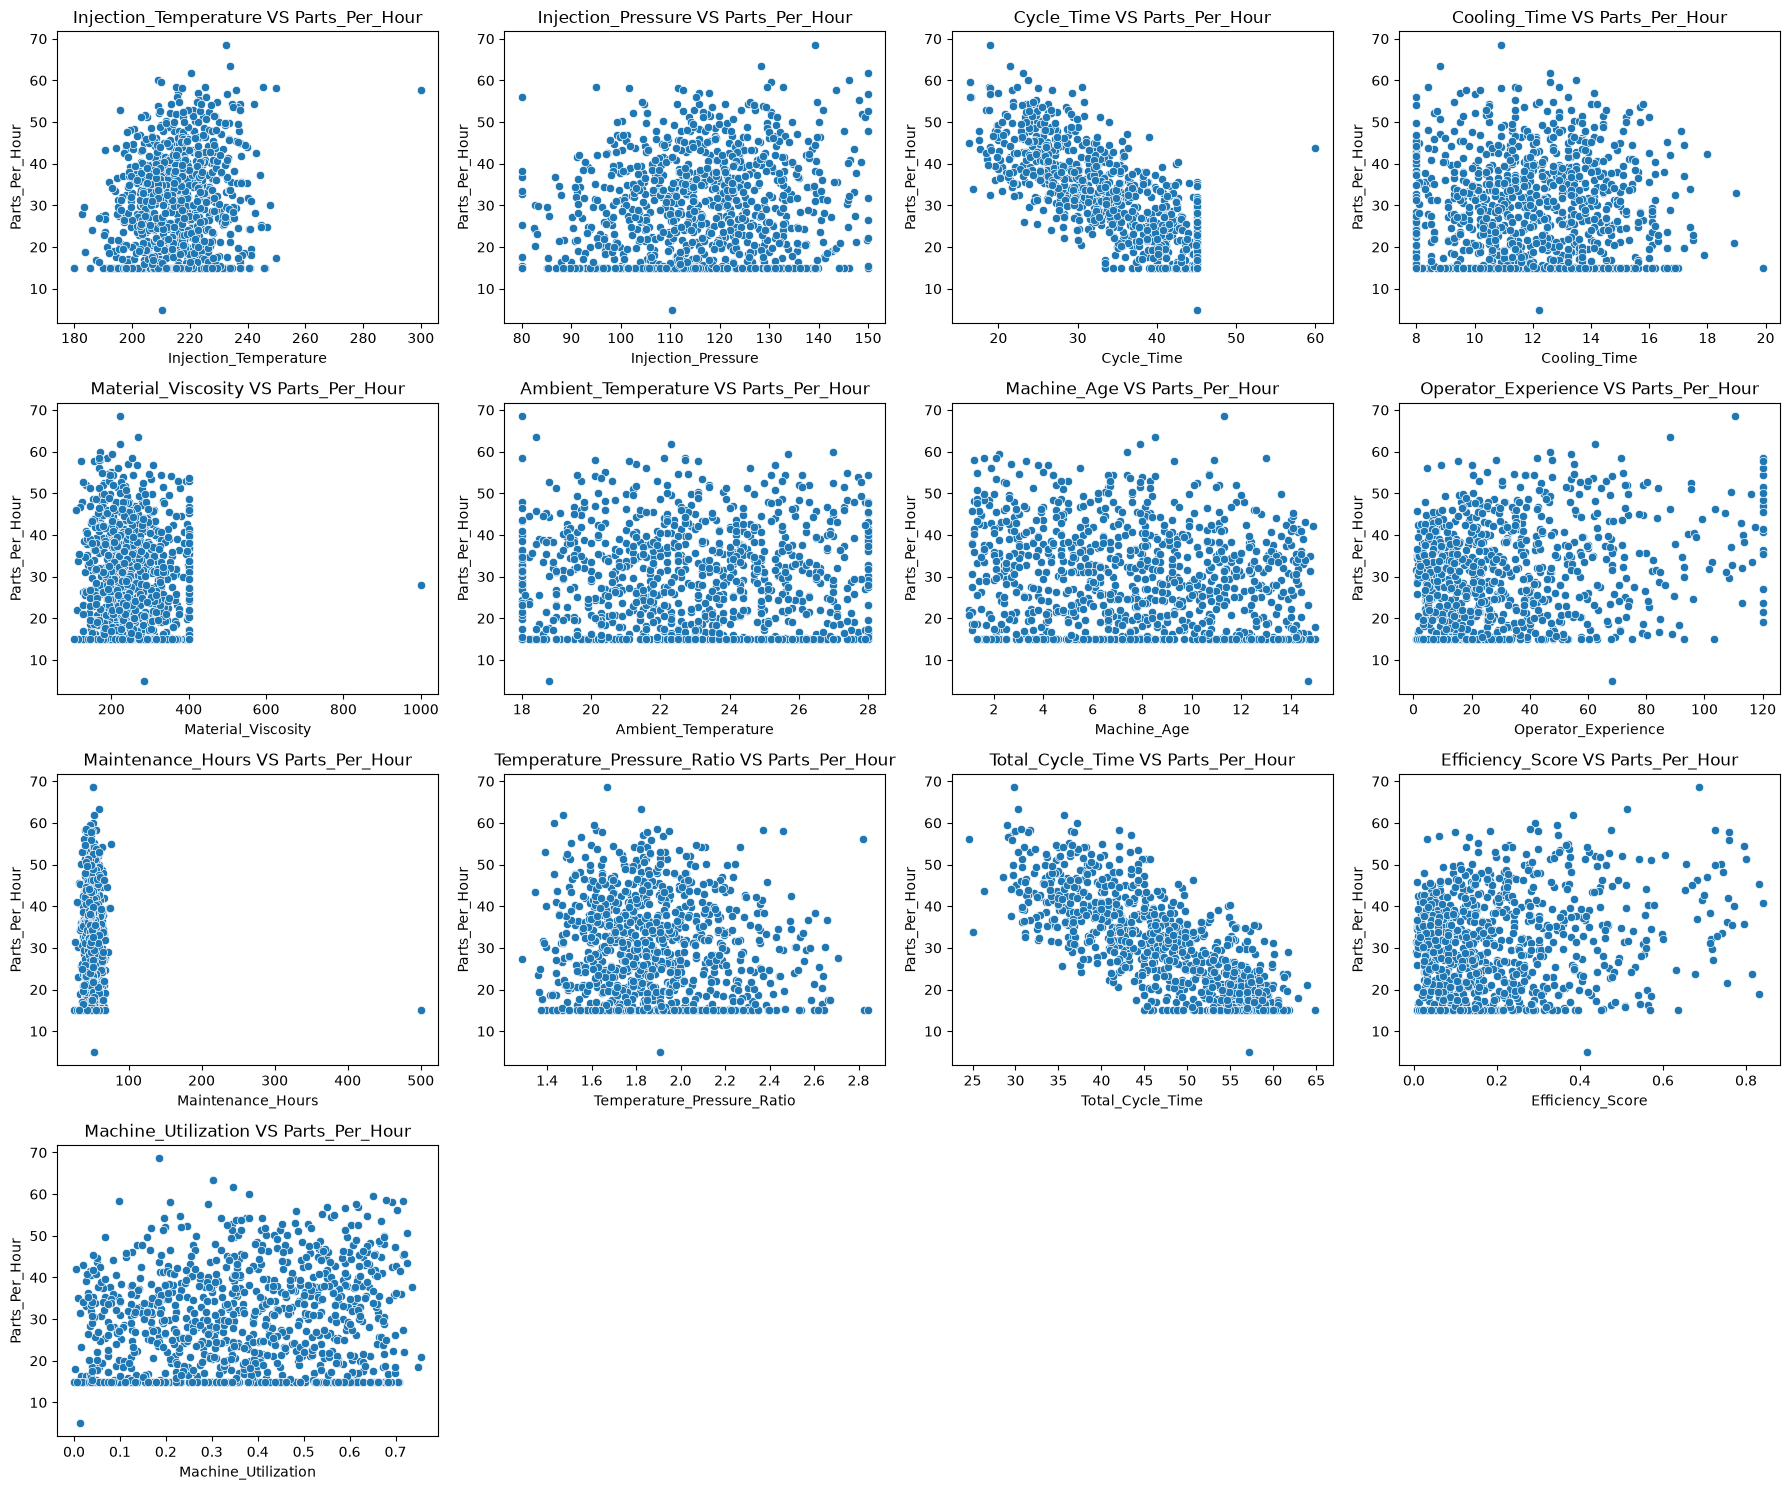

In [8]:
Features = ['Injection_Temperature', 'Injection_Pressure', 'Cycle_Time',
       'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature',
       'Machine_Age', 'Operator_Experience', 'Maintenance_Hours',
       'Temperature_Pressure_Ratio', 'Total_Cycle_Time', 'Efficiency_Score',
       'Machine_Utilization']
Target = 'Parts_Per_Hour'
fig,axes = plt.subplots(4,4,figsize=(18,15))
axes= axes.flatten()
for i ,features in enumerate(Features):
    sns.scatterplot(data=df,x=features,y=Target,ax=axes[i])
    axes[i].set_title(f"{features} VS {Target}")
    axes[i].set_xlabel(features)
    axes[i].set_ylabel(Target)

for i in range(len(Features),len(axes)):
    axes[i].set_visible(False)
plt.tight_layout()
plt.show()


#### Categorical feature Analysis

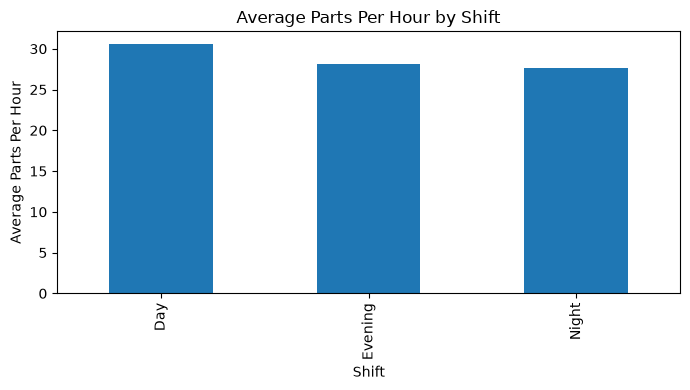

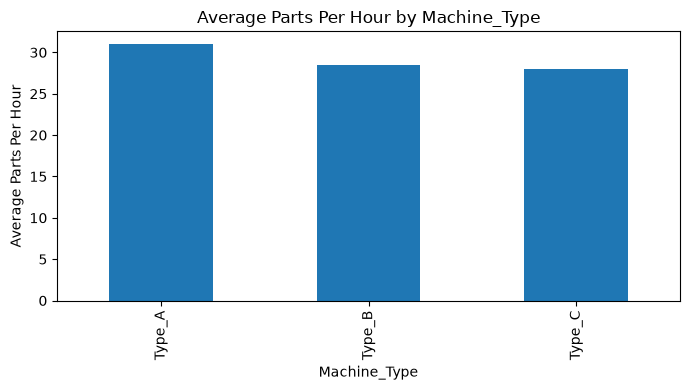

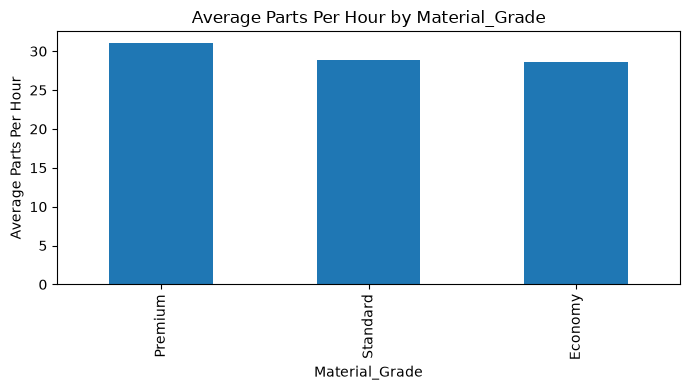

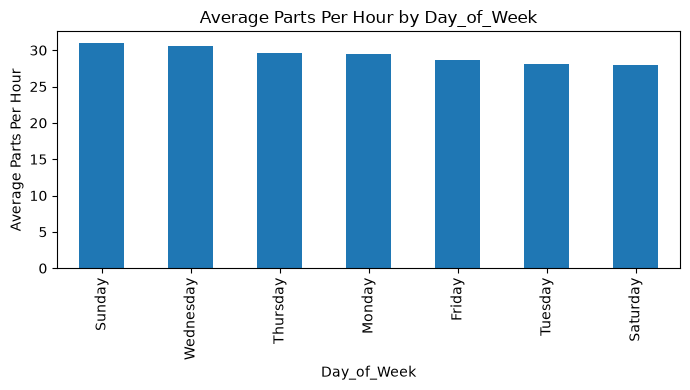

In [9]:
categorical_eda = ['Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week']
for col in categorical_eda:
    avg = df.groupby(col)['Parts_Per_Hour'].mean().sort_values(ascending=False) # calculate average parts per hour for each category
    plt.figure(figsize=(7,4))
    avg.plot(kind='bar')
    plt.title(f'Average Parts Per Hour by {col}')
    plt.xlabel(col)
    plt.ylabel('Average Parts Per Hour')
   
    plt.tight_layout()
    plt.show()

In [10]:
correlation = df[numerical_columns].corrwith(df["Parts_Per_Hour"])
print(correlation)

Injection_Temperature         0.184348
Injection_Pressure            0.160512
Cycle_Time                   -0.819577
Cooling_Time                  0.006143
Material_Viscosity           -0.080443
Ambient_Temperature           0.011662
Machine_Age                  -0.174579
Operator_Experience           0.301113
Maintenance_Hours            -0.032942
Temperature_Pressure_Ratio   -0.086348
Total_Cycle_Time             -0.793055
Efficiency_Score              0.287002
Machine_Utilization           0.174631
Parts_Per_Hour                1.000000
dtype: float64


#### Correlation

Correlation Matrix:
                             Injection_Temperature  Injection_Pressure  \
Injection_Temperature                    1.000000           -0.046148   
Injection_Pressure                      -0.046148            1.000000   
Cycle_Time                              -0.030086           -0.000979   
Cooling_Time                            -0.034896            0.009252   
Material_Viscosity                      -0.027496           -0.030679   
Ambient_Temperature                     -0.050812            0.021891   
Machine_Age                              0.062135           -0.025136   
Operator_Experience                      0.022174            0.026414   
Maintenance_Hours                       -0.025770           -0.009393   
Temperature_Pressure_Ratio               0.399607           -0.914940   
Total_Cycle_Time                        -0.043503            0.005515   
Efficiency_Score                         0.019923            0.022553   
Machine_Utilization           

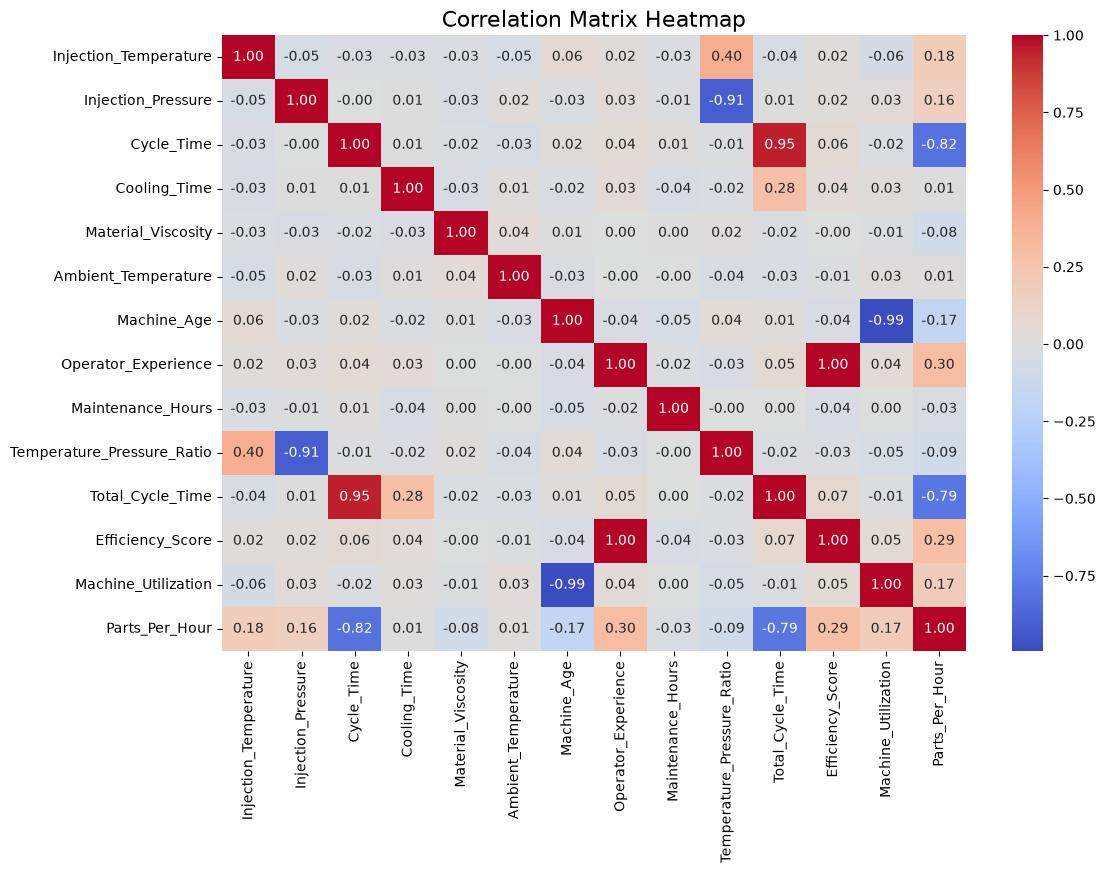

In [11]:
corr_matrix = df.corr(numeric_only=True)

# Display the correlation matrix
print("Correlation Matrix:\n", corr_matrix)

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix Heatmap", fontsize=16)
plt.show()

#### Outliers Detection

In [12]:

for col in numerical_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    count = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()
    if count:
        print(f'{col}: {count} outliers | lower={lower_limit:.2f}, upper={upper_limit:.2f}')
  



Injection_Temperature: 9 outliers | lower=183.80, upper=246.20
Cooling_Time: 3 outliers | lower=5.38, upper=18.38
Material_Viscosity: 1 outliers | lower=59.55, upper=436.75
Operator_Experience: 44 outliers | lower=-40.68, upper=93.93
Maintenance_Hours: 7 outliers | lower=30.00, upper=70.00
Temperature_Pressure_Ratio: 18 outliers | lower=1.15, upper=2.58
Efficiency_Score: 40 outliers | lower=-0.26, upper=0.59


In [13]:
# Handle numerical outliers using IQR capping

df_capped = df.copy()

for col in numerical_columns :

    Q1 = df_capped[col].quantile(0.25)
    Q3 = df_capped[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_capped[col] = df_capped[col].clip(
        lower_limit,
        upper_limit
    )

#### Traing Testing split


In [14]:
TARGET = 'Parts_Per_Hour'
NUMERIC_FEATURES = [
    'Injection_Temperature', 'Injection_Pressure', 'Cycle_Time',
    'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature',
    'Machine_Age', 'Operator_Experience', 'Maintenance_Hours',
    'Efficiency_Score', 'Machine_Utilization'
]
CATEGORICAL_FEATURES = ['Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week']

X = df_capped.drop(columns=[TARGET, 'Timestamp', 'Total_Cycle_Time', 'Temperature_Pressure_Ratio'])
y = df_capped[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))


Training rows: 799
Testing rows: 200


#### Data Preprocessing

In [24]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore',drop="first"))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, NUMERIC_FEATURES),
    ('cat', categorical_pipeline, CATEGORICAL_FEATURES)
])

linear_model = Pipeline([
    ('prep', preprocessor),
    ('model', LinearRegression())
])

#### Model Evaluation

In [16]:

linear_model.fit(X_train, y_train)

y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)
#trainig data evaluation
mae_train = mean_absolute_error(y_train,y_train_pred)
mse_train = mean_squared_error(y_train,y_train_pred)
rmse_train = root_mean_squared_error(y_train,y_train_pred)
r2_train = r2_score(y_train, y_train_pred)

#testing data evaluation
mae_test = mean_absolute_error(y_test,y_test_pred)
mse_test = mean_squared_error(y_test,y_test_pred)
rmse_test = root_mean_squared_error(y_test,y_test_pred)
r2_test = r2_score(y_test,y_test_pred)


print("Training: ")
print(f"MAE : {mae_train}")
print(f"MSE : {mse_train}")
print(f"RMSE :{rmse_train}")
print(f"R2 : {r2_train}")

print("Testing :")
print(f"MAE : {mae_test}")
print(f"MSE : {mse_test}")
print(f"RMSE : {rmse_test}")
print(f"R2 : {r2_test}")


Training: 
MAE : 2.5164095142501006
MSE : 10.382061417198843
RMSE :3.2221206397648805
R2 : 0.9284331790934267
Testing :
MAE : 2.8638493974549353
MSE : 20.612398441553687
RMSE : 4.540087933240246
R2 : 0.8466243858590835


#### Cross Validation 


In [17]:

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(linear_model, X_train, y_train, cv=cv, scoring='r2')
print('R2 scores:', cv_scores)
print('Mean R2:', cv_scores.mean())
print('Std R2:', cv_scores.std())


R2 scores: [0.91779923 0.92102076 0.92216914 0.9194015  0.92975489]
Mean R2: 0.9220291046248622
Std R2: 0.004135706216153928


#### Actual vs Predicted graph

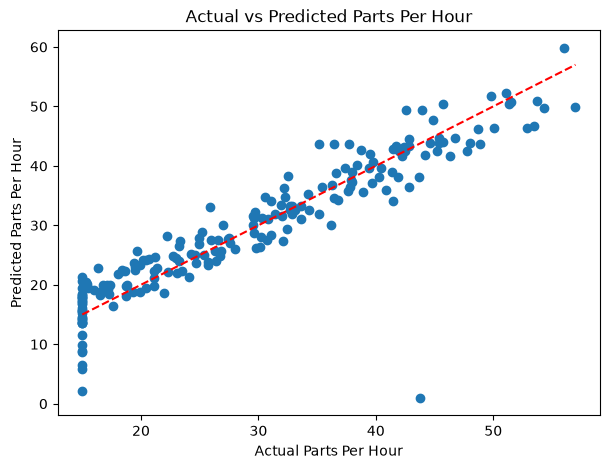

In [18]:

plt.figure(figsize=(7,5))
plt.scatter(y_test, y_test_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],color="red", linestyle='--')
plt.xlabel('Actual Parts Per Hour')
plt.ylabel('Predicted Parts Per Hour')
plt.title('Actual vs Predicted Parts Per Hour')
plt.show()

#### Feature Coefficient

In [19]:
# Get feature names after preprocessing
feature_names = linear_model.named_steps['prep'].get_feature_names_out()

# Get coefficients from Linear Regression
coefficients = linear_model.named_steps['model'].coef_

# Create coefficient dataframe
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Sort by absolute coefficient
coef_df['Absolute_Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values(
    by='Absolute_Coefficient',
    ascending=False
)

display(coef_df)

,Feature,Coefficient,Absolute_Coefficient
2,num__Cycle_Time,-10.290464,10.290464
12,cat__Shift_Night,-4.021070,4.021070
6,num__Machine_Age,-3.782732,3.782732
14,cat__Machine_Type_Type_C,-3.748800,3.748800
15,cat__Material_Grade_Premium,3.199704,3.199704
9,num__Efficiency_Score,3.197870,3.197870
13,cat__Machine_Type_Type_B,-2.337805,2.337805
10,num__Machine_Utilization,-2.096931,2.096931
0,num__Injection_Temperature,2.084835,2.084835
1,num__Injection_Pressure,1.841651,1.841651


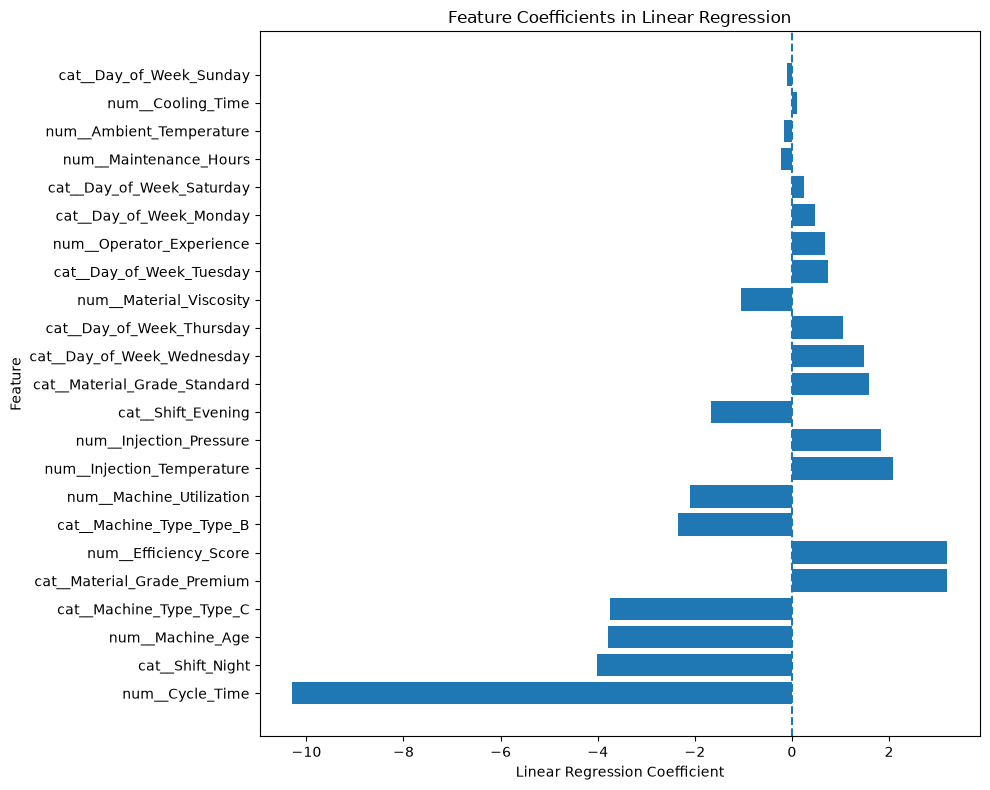

In [25]:
plt.figure(figsize=(10, 8))

plt.barh(
    coef_df['Feature'],
    coef_df['Coefficient']
)

plt.axvline(0, linestyle='--')

plt.xlabel('Linear Regression Coefficient')
plt.ylabel('Feature')
plt.title('Feature Coefficients in Linear Regression')

plt.tight_layout()
plt.show()

#### Residual plot

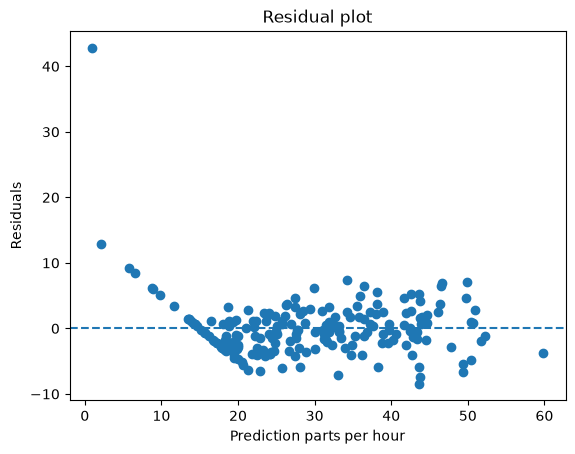

In [21]:
residuals =y_test - y_test_pred
plt.Figure(figsize=(7,8))
plt.axhline(y=0,linestyle="--")
plt.scatter(y_test_pred,residuals)
plt.title("Residual plot")
plt.xlabel("Prediction parts per hour")
plt.ylabel("Residuals")
plt.show()


#### Streamlit

In [22]:
joblib.dump(linear_model,"capstone_project.joblib")

model = joblib.load("capstone_project.joblib")


st.set_page_config(
    page_title="Manufacturing Output Prediction",
    page_icon="🏭",
    layout="wide"
)

st.title("🏭 Manufacturing Equipment Output Prediction")
st.write("Predict the hourly production output of an injection molding machine ")

st.divider()
st.subheader("⚙️ Machine Parameters")

col1, col2 = st.columns(2)

with col1:
    Injection_Temperature = st.number_input("Injection Temperature" )  
    Injection_Pressure = st.number_input( "Injection Pressure" )
    Cycle_Time = st.number_input("Cycle Time" )

with col2:
   Cooling_Time = st.number_input( "Cooling Time" )
   Machine_Utilization = st.number_input( "Machine Utilization" )
   Efficiency_Score= st.number_input( "Efficiency Score")

st.subheader("👷 Operator & Maintenance")
col1, col2 = st.columns(2)
with col1:
    Operator_Experience = st.number_input( "Operator Experience" )

with col2:
    Maintenance_Hours = st.number_input("Maintenance Hours" )

st.subheader("🧪 Material Information")

col1, col2 = st.columns(2)

with col1:
   Material_Viscosity = st.number_input( "Material Viscosity" )
with col2:
    Material_Grade = st.selectbox("Material Grade", ["Economy", "Standard", "Premium"])


st.subheader("🌡️ Environmental Information")

col1, col2 = st.columns(2)

with col1:
    Ambient_Temperature = st.number_input("Ambient Temperature")

with col2:
    Day_of_Week = st.selectbox(
        "Day of Week",
        [
            "Monday",
            "Tuesday",
            "Wednesday",
            "Thursday",
            "Friday",
            "Saturday",
            "Sunday"
        ]
    )

st.subheader("🏭 Machine & Shift Information")

col1, col2 = st.columns(2)

with col1:
    Machine_Type = st.selectbox( "Machine Type",["Type_A", "Type_B","Type_C"] )
    Machine_Age = st.number_input("Machine Age")

with col2:
    Shift = st.selectbox( "Shift",  ["Day", "Night", "Evening"]  ) 



input_row =pd.DataFrame( [{
    "Injection_Temperature":Injection_Temperature,
    "Injection_Pressure":Injection_Pressure,
    "Cycle_Time":Cycle_Time,
    "Cooling_Time":Cooling_Time,
    "Material_Viscosity":Material_Viscosity,
    "Machine_Age":Machine_Age
    "Ambient_Temperature":Ambient_Temperature,
    "Operator_Experience":Operator_Experience,
    "Maintenance_Hours":Maintenance_Hours,
    "Efficiency_Score":Efficiency_Score,
    "Machine_Utilization":Machine_Utilization,
    "Shift":Shift,
    "Machine_Type":Machine_Type,
    "Material_Grade":Material_Grade,
    "Day_of_Week":Day_of_Week  
}])
prediction = linear_model.predict([input_row][0])

st.divider()

if st.button("🔮 Predict Parts Per Hour", use_container_width=True):
    st.success(f"Parts per hour : {prediction:.2f}")

    

SyntaxError: invalid syntax (3918023022.py, line 89)